# S10 · Series de tiempo e inferencia en streaming con MLlib

**Equipo 10 · BIG IMPACT · Juliaca**

**Pregunta de negocio:** ¿se puede predecir la temperatura de Juliaca con 1 hora de anticipación y avisar si habrá helada (≤ 0 °C), mejor que simplemente asumir que "la próxima hora será igual que ahora"?

**Plan:** preparar la serie (`lead`) → partir en orden cronológico → línea base de persistencia → LinearRegression y RandomForest → guardar el mejor `PipelineModel` → aplicarlo en streaming sobre `heladas-eventos`.

In [2]:
from pyspark.sql import SparkSession

spark = (SparkSession.builder
    .appName("sesion10-series-tiempo")
    .config("spark.sql.shuffle.partitions", "3")
    .config("spark.jars.packages", "org.apache.spark:spark-sql-kafka-0-10_2.13:4.2.0")
    .getOrCreate())

spark.sparkContext.setLogLevel("WARN")
print("Spark", spark.version)

Spark 4.2.0


## 2. Carga del Gold histórico (batch de U1) y verificación de la serie

Se usa la capa Gold de la Unidad I (`clima_particionado`): una fila por hora de Juliaca. Se verifica el rango de fechas (el histórico no debe pasar del 1 de octubre de 2026), los nulos y los huecos horarios.

In [3]:
from pyspark.sql import functions as F

GOLD = "/opt/u1/s03-calidad-particionamiento/artifacts/clima_particionado"

gold = (spark.read.parquet(GOLD)
        .filter(F.col("hora") <= F.lit("2026-10-01 23:59:59").cast("timestamp"))
        .orderBy("hora"))

print("Filas:", gold.count())
gold.select(F.min("hora").alias("desde"), F.max("hora").alias("hasta")).show(truncate=False)

print("Nulos por columna:")
gold.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in gold.columns]).show()

# huecos: diferencia en horas entre filas consecutivas
from pyspark.sql.window import Window
w = Window.orderBy("hora")
huecos = (gold.withColumn("dif_h", (F.col("hora").cast("long") - F.lag("hora").over(w).cast("long")) / 3600)
          .groupBy("dif_h").count().orderBy("dif_h"))
huecos.show(10)

gold.show(5, truncate=False)

Filas: 146832
+-------------------+-------------------+
|desde              |hasta              |
+-------------------+-------------------+
|2010-01-01 00:00:00|2026-10-01 23:00:00|
+-------------------+-------------------+

Nulos por columna:
+------+----+-----------+----------+-------+---------+-------+-------------+----+---+
|ciudad|hora|temperatura|puntoRocio|humedad|nubosidad|presion|precipitacion|anio|mes|
+------+----+-----------+----------+-------+---------+-------+-------------+----+---+
|     0|   0|          0|         0|      0|        0|      0|            0|   0|  0|
+------+----+-----------+----------+-------+---------+-------+-------------+----+---+



26/11/20 10:32:35 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/20 10:32:35 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/20 10:32:36 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/20 10:32:36 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/20 10:32:37 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/20 10:32:37 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
          

+-----+------+
|dif_h| count|
+-----+------+
| NULL|     1|
|  1.0|146831|
+-----+------+

+-------+-------------------+-----------+----------+-------+---------+-------+-------------+----+---+
|ciudad |hora               |temperatura|puntoRocio|humedad|nubosidad|presion|precipitacion|anio|mes|
+-------+-------------------+-----------+----------+-------+---------+-------+-------------+----+---+
|Juliaca|2010-01-01 00:00:00|5.7        |2.7       |78     |19       |1019.0 |0.0          |2010|1  |
|Juliaca|2010-01-01 01:00:00|4.9        |2.2       |75     |19       |1019.0 |0.0          |2010|1  |
|Juliaca|2010-01-01 02:00:00|4.7        |1.2       |73     |18       |1018.0 |0.0          |2010|1  |
|Juliaca|2010-01-01 03:00:00|4.4        |0.6       |70     |18       |1018.0 |0.0          |2010|1  |
|Juliaca|2010-01-01 04:00:00|4.1        |-2.2      |64     |20       |1019.0 |0.0          |2010|1  |
+-------+-------------------+-----------+----------+-------+---------+-------+-------------+-

## 3. Objetivo (`lead`) y variables de entrada

Se predice la **temperatura de la hora siguiente** (`temp_h1`) con `lead(temperatura, 1)` sobre la serie ordenada. También se calcula `helada_h1` (1 si `temp_h1 ≤ 0 °C`), para evaluar la alerta.

Las variables de entrada se limitan a lo que **también llega en el evento de Kafka** (`temperatura`, `puntoRocio`, `humedad`, `nubosidad`) más la hora del día y el mes, para que el mismo modelo sirva luego en streaming sin reentrenar ni reconstruir variables.

In [4]:
from pyspark.sql.window import Window

w = Window.partitionBy("ciudad").orderBy("hora")

serie = (gold
    .withColumn("temp_h1", F.lead("temperatura", 1).over(w))
    .withColumn("helada_h1", (F.col("temp_h1") <= 0).cast("int"))
    .withColumn("hora_dia", F.hour("hora"))
    .withColumn("mes", F.month("hora"))
    .dropna(subset=["temp_h1"]))          # la última hora no tiene "siguiente"

FEATURES = ["temperatura", "puntoRocio", "humedad", "nubosidad", "hora_dia", "mes"]

print("Filas con objetivo:", serie.count())
serie.select("hora", *FEATURES, "temp_h1", "helada_h1").show(8, truncate=False)

print("Heladas a 1 h (temp_h1 <= 0):")
serie.groupBy("helada_h1").count().show()

Filas con objetivo: 146831
+-------------------+-----------+----------+-------+---------+--------+---+-------+---------+
|hora               |temperatura|puntoRocio|humedad|nubosidad|hora_dia|mes|temp_h1|helada_h1|
+-------------------+-----------+----------+-------+---------+--------+---+-------+---------+
|2010-01-01 00:00:00|5.7        |2.7       |78     |19       |0       |1  |4.9    |0        |
|2010-01-01 01:00:00|4.9        |2.2       |75     |19       |1       |1  |4.7    |0        |
|2010-01-01 02:00:00|4.7        |1.2       |73     |18       |2       |1  |4.4    |0        |
|2010-01-01 03:00:00|4.4        |0.6       |70     |18       |3       |1  |4.1    |0        |
|2010-01-01 04:00:00|4.1        |-2.2      |64     |20       |4       |1  |4.9    |0        |
|2010-01-01 05:00:00|4.9        |-2.5      |59     |23       |5       |1  |5.8    |0        |
|2010-01-01 06:00:00|5.8        |-2.9      |53     |26       |6       |1  |7.9    |0        |
|2010-01-01 07:00:00|7.9        |

## 4. Partición cronológica (sin mezclar el futuro con el pasado)

En series de tiempo no se usa `randomSplit`: mezclaría horas futuras en el entrenamiento y daría métricas optimistas. Se entrena con el 80 % más antiguo y se evalúa con el 20 % más reciente.

In [5]:
corte_seg = serie.approxQuantile(
    "hora_seg", [0.8], 0.0001)[0] if "hora_seg" in serie.columns else None

serie = serie.withColumn("hora_seg", F.col("hora").cast("long"))
corte_seg = serie.approxQuantile("hora_seg", [0.8], 0.0001)[0]
corte = F.lit(int(corte_seg)).cast("timestamp")

train = serie.filter(F.col("hora") <= corte)
test  = serie.filter(F.col("hora") >  corte)

print("Fecha de corte:", train.agg(F.max("hora")).first()[0])
for nombre, d in [("train", train), ("test", test)]:
    r = d.agg(F.count("*").alias("filas"),
              F.min("hora").alias("desde"),
              F.max("hora").alias("hasta"),
              F.sum("helada_h1").alias("heladas")).first()
    print(f"{nombre:5} filas={r['filas']:>6}  {r['desde']} → {r['hasta']}  heladas={r['heladas']}")

Fecha de corte: 2023-05-26 21:00:00
train filas=117454  2010-01-01 00:00:00 → 2023-05-26 21:00:00  heladas=2573
test  filas= 29377  2023-05-26 22:00:00 → 2026-10-01 22:00:00  heladas=607


## 5. Línea base: persistencia

La referencia a vencer es la más simple: *"la temperatura de la próxima hora será igual a la actual"* (`pred = temperatura`). Un modelo solo tiene valor si mejora a esta línea base. Se mide el error de la temperatura (RMSE, MAE) y la calidad de la alerta de helada (`pred ≤ 0 °C`) con precisión, recall y F1, porque la clase helada es rara (2 %).

In [8]:
resultados = []

media_test = float(test.agg(F.avg("temp_h1")).first()[0])

def evaluar(df, col_pred, nombre):
    d = (df.withColumn("err", F.col(col_pred) - F.col("temp_h1"))
           .withColumn("alerta", (F.col(col_pred) <= 0).cast("int")))
    r = d.agg(
        F.sqrt(F.avg(F.col("err") ** 2)).alias("rmse"),
        F.avg(F.abs("err")).alias("mae"),
        F.avg(F.col("err") ** 2).alias("mse"),
        F.avg((F.col("temp_h1") - F.lit(media_test)) ** 2).alias("var_y"),
        F.sum(F.when((F.col("alerta") == 1) & (F.col("helada_h1") == 1), 1).otherwise(0)).alias("tp"),
        F.sum(F.when((F.col("alerta") == 1) & (F.col("helada_h1") == 0), 1).otherwise(0)).alias("fp"),
        F.sum(F.when((F.col("alerta") == 0) & (F.col("helada_h1") == 1), 1).otherwise(0)).alias("fn"),
    ).first()
    prec = r["tp"] / (r["tp"] + r["fp"]) if (r["tp"] + r["fp"]) else 0.0
    rec  = r["tp"] / (r["tp"] + r["fn"]) if (r["tp"] + r["fn"]) else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    fila = {"modelo": nombre, "rmse": round(r["rmse"], 3), "mae": round(r["mae"], 3),
            "r2": round(1 - r["mse"] / r["var_y"], 4),
            "precision": round(prec, 3), "recall": round(rec, 3), "f1": round(f1, 3),
            "tp": r["tp"], "fp": r["fp"], "fn": r["fn"]}
    resultados[:] = [x for x in resultados if x["modelo"] != nombre] + [fila]
    return fila

base = test.withColumn("pred_persistencia", F.col("temperatura"))
print(evaluar(base, "pred_persistencia", "Persistencia"))

{'modelo': 'Persistencia', 'rmse': 1.499, 'mae': 1.142, 'r2': 0.9021, 'precision': 0.677, 'recall': 0.677, 'f1': 0.677, 'tp': 411, 'fp': 196, 'fn': 196}


## 6. Modelo 1: LinearRegression

Se arma un `Pipeline` (`VectorAssembler` → `LinearRegression`) para poder guardarlo y reutilizarlo después en streaming. Se entrena con `train` y se evalúa con `test`, con las mismas métricas que la persistencia.

In [9]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression

ensamblador = VectorAssembler(inputCols=FEATURES, outputCol="features")
lr = LinearRegression(featuresCol="features", labelCol="temp_h1", predictionCol="pred_lr")

pipe_lr = Pipeline(stages=[ensamblador, lr])
modelo_lr = pipe_lr.fit(train)

pred_lr = modelo_lr.transform(test)
print(evaluar(pred_lr, "pred_lr", "LinearRegression"))

print("\nCoeficientes:")
for nombre, coef in zip(FEATURES, modelo_lr.stages[-1].coefficients):
    print(f"  {nombre:12} {coef:+.4f}")
print(f"  {'intercepto':12} {modelo_lr.stages[-1].intercept:+.4f}")

26/11/20 10:39:04 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
26/11/20 10:39:05 WARN Instrumentation: [41d8bc95] regParam is zero, which might cause numerical instability and overfitting.
netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory
netlib-lapack: JNI_OnLoad: dlopen(liblapack.so.3) failed: liblapack.so.3: cannot open shared object file: No such file or directory


{'modelo': 'LinearRegression', 'rmse': 1.409, 'mae': 1.135, 'r2': 0.9134, 'precision': 0.723, 'recall': 0.336, 'f1': 0.459, 'tp': 204, 'fp': 78, 'fn': 403}

Coeficientes:
  temperatura  +0.8313
  puntoRocio   +0.1665
  humedad      -0.0548
  nubosidad    -0.0006
  hora_dia     -0.0642
  mes          -0.0124
  intercepto   +5.6145


## 7. Modelo 2: RandomForestRegressor

Segundo algoritmo, no lineal: puede capturar interacciones entre humedad, punto de rocío y hora del día (por ejemplo, noches despejadas y secas que enfrían más). Se evalúa con las mismas métricas que los modelos anteriores.

In [10]:
from pyspark.ml.regression import RandomForestRegressor

rf = RandomForestRegressor(featuresCol="features", labelCol="temp_h1",
                           predictionCol="pred_rf",
                           numTrees=100, maxDepth=8, seed=42)

pipe_rf = Pipeline(stages=[VectorAssembler(inputCols=FEATURES, outputCol="features"), rf])
modelo_rf = pipe_rf.fit(train)

pred_rf = modelo_rf.transform(test)
print(evaluar(pred_rf, "pred_rf", "RandomForest"))

print("\nImportancia de variables:")
imp = modelo_rf.stages[-1].featureImportances
for nombre, v in sorted(zip(FEATURES, imp), key=lambda x: -x[1]):
    print(f"  {nombre:12} {v:.4f}")

26/11/20 10:40:50 WARN DAGScheduler: Broadcasting large task binary with size 1028.2 KiB
26/11/20 10:40:54 WARN DAGScheduler: Broadcasting large task binary with size 1973.1 KiB
26/11/20 10:40:59 WARN DAGScheduler: Broadcasting large task binary with size 3.8 MiB
26/11/20 10:41:04 WARN DAGScheduler: Broadcasting large task binary with size 1238.5 KiB
[Stage 216:>                                                        (0 + 1) / 1]

{'modelo': 'RandomForest', 'rmse': 0.971, 'mae': 0.73, 'r2': 0.9589, 'precision': 0.912, 'recall': 0.684, 'f1': 0.782, 'tp': 415, 'fp': 40, 'fn': 192}

Importancia de variables:
  temperatura  0.4993
  hora_dia     0.3488
  humedad      0.0947
  puntoRocio   0.0319
  mes          0.0193
  nubosidad    0.0059


## 8. Comparación de modelos contra el baseline

Tabla única con las métricas de temperatura (RMSE, MAE, R²) y de alerta de helada (precisión, recall, F1) sobre el conjunto de prueba (2023-05-26 → 2026-10-01). La pregunta de la guía: ¿la complejidad adicional se justificó?

,rmse,mae,r2,precision,recall,f1,tp,fp,fn
modelo,,,,,,,,,
Persistencia,1.499,1.142,0.9021,0.677,0.677,0.677,411,196,196
LinearRegression,1.409,1.135,0.9134,0.723,0.336,0.459,204,78,403
RandomForest,0.971,0.730,0.9589,0.912,0.684,0.782,415,40,192


Mejora del RMSE del RandomForest frente a la persistencia: 35.2 %


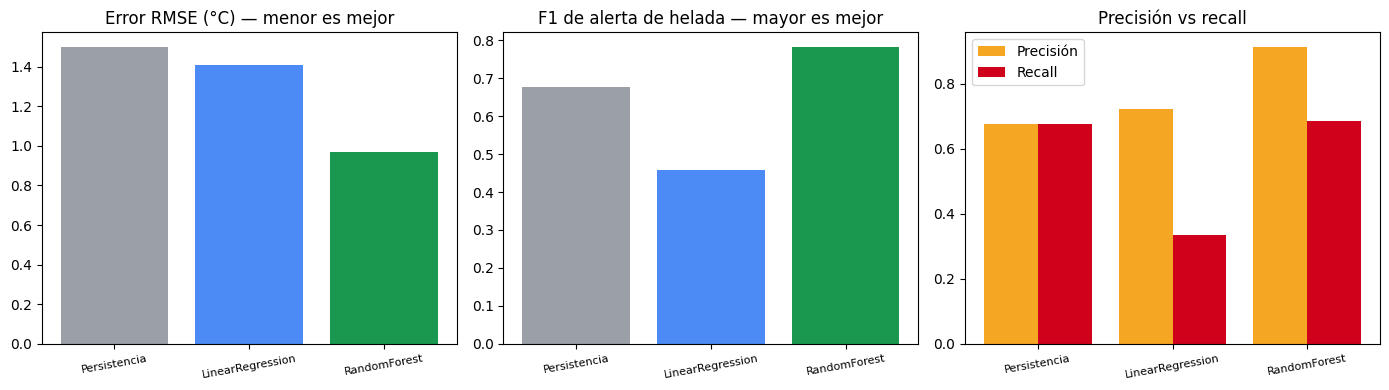

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

orden = ["Persistencia", "LinearRegression", "RandomForest"]
tabla = (pd.DataFrame(resultados).set_index("modelo").loc[orden])
display(tabla)

mejora = (1 - tabla.loc["RandomForest", "rmse"] / tabla.loc["Persistencia", "rmse"]) * 100
print(f"Mejora del RMSE del RandomForest frente a la persistencia: {mejora:.1f} %")

colores = ["#9aa0a6", "#4c8bf5", "#1a9850"]
fig, ax = plt.subplots(1, 3, figsize=(14, 4))

ax[0].bar(orden, tabla["rmse"], color=colores)
ax[0].set_title("Error RMSE (°C) — menor es mejor")
ax[1].bar(orden, tabla["f1"], color=colores)
ax[1].set_title("F1 de alerta de helada — mayor es mejor")
x = range(len(orden))
ax[2].bar([i - 0.2 for i in x], tabla["precision"], 0.4, label="Precisión", color="#f5a623")
ax[2].bar([i + 0.2 for i in x], tabla["recall"], 0.4, label="Recall", color="#d0021b")
ax[2].set_xticks(list(x)); ax[2].set_xticklabels(orden)
ax[2].set_title("Precisión vs recall"); ax[2].legend()

for a in ax:
    a.tick_params(axis="x", labelsize=8)
    for lab in a.get_xticklabels():
        lab.set_rotation(10)
plt.tight_layout()
plt.show()

## 9. Guardar y recargar el `PipelineModel` ganador

Se guarda el pipeline completo (`VectorAssembler` + `RandomForestRegressor`) para aplicarlo después sobre Kafka sin reentrenar. Para comprobar que el guardado es fiel, se recarga y se verifica que da **las mismas predicciones** que el modelo en memoria.

In [12]:
from pyspark.ml import PipelineModel

RUTA_MODELO = "./artifacts/modelo_rf_temp_h1"

modelo_rf.write().overwrite().save(RUTA_MODELO)
print("Modelo guardado en:", RUTA_MODELO)

modelo_cargado = PipelineModel.load(RUTA_MODELO)

muestra = test.limit(2000)
a = modelo_rf.transform(muestra).select("hora", F.col("pred_rf").alias("pred_memoria"))
b = modelo_cargado.transform(muestra).select("hora", F.col("pred_rf").alias("pred_cargado"))

comp = a.join(b, "hora").withColumn("dif", F.abs(F.col("pred_memoria") - F.col("pred_cargado")))
comp.agg(F.count("*").alias("filas"), F.max("dif").alias("dif_maxima")).show()
comp.orderBy("hora").show(5, truncate=False)

import os
for raiz, _, archivos in os.walk(RUTA_MODELO):
    print(raiz.replace(RUTA_MODELO, "modelo"), len(archivos), "archivos")

Modelo guardado en: ./artifacts/modelo_rf_temp_h1
+-----+----------+
|filas|dif_maxima|
+-----+----------+
| 2000|       0.0|
+-----+----------+

+-------------------+------------------+------------------+---+
|hora               |pred_memoria      |pred_cargado      |dif|
+-------------------+------------------+------------------+---+
|2023-05-26 22:00:00|5.899324958103112 |5.899324958103112 |0.0|
|2023-05-26 23:00:00|5.867629916119125 |5.867629916119125 |0.0|
|2023-05-27 00:00:00|5.326795300305754 |5.326795300305754 |0.0|
|2023-05-27 01:00:00|5.1302358125257115|5.1302358125257115|0.0|
|2023-05-27 02:00:00|4.03958426292828  |4.03958426292828  |0.0|
+-------------------+------------------+------------------+---+
only showing top 5 rows
modelo 0 archivos
modelo/metadata 4 archivos
modelo/stages 0 archivos
modelo/stages/0_VectorAssembler_fe640dc5f60b 0 archivos
modelo/stages/0_VectorAssembler_fe640dc5f60b/metadata 4 archivos
modelo/stages/1_RandomForestRegressor_94c866b7bd6e 0 archivos
m

## 10. Inspección de los eventos reales en `heladas-eventos`

Lectura **por lotes** (no streaming) de lo que ya hay en el topic, solo para ver el formato de los campos que consumirá el modelo: `temperatura`, `puntoRocio`, `humedad`, `nubosidad` y la hora de observación. Hay que verificar que `observadoEn` esté en hora local de Juliaca, igual que la columna `hora` del Gold con que se entrenó.

In [13]:
KAFKA = "kafka:9092"
TOPIC = "heladas-eventos"

crudo_lote = (spark.read.format("kafka")
    .option("kafka.bootstrap.servers", KAFKA)
    .option("subscribe", TOPIC)
    .option("startingOffsets", "earliest")
    .option("endingOffsets", "latest")
    .load())

print("Eventos en el topic:", crudo_lote.count())

(crudo_lote
    .select("partition", "offset", F.col("timestamp").alias("publicado_utc"),
            F.col("value").cast("string").alias("json"))
    .orderBy(F.desc("offset"))
    .show(5, truncate=False))

Eventos en el topic: 1553
+---------+------+-----------------------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|partition|offset|publicado_utc          |json                                                                                                                                                                                                         |
+---------+------+-----------------------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|1        |1547  |2026-11-20 10:44:13.516|{"tipoEvento": "clima.lectura", "ciudad": "Juliaca", "temperatura": 7.4, "puntoRocio": 3.9, "humedad": 78, "nubosidad": 62, "origen": "weatherapi", "observadoEn": 1795170600000, "timest

## 11. Esquema del evento y construcción de variables (verificación en lote)

El evento trae `observadoEn` como epoch en milisegundos **UTC**; el Gold se entrenó con la hora **local de Juliaca** (UTC-5). Se convierte con `from_utc_timestamp(..., "America/Lima")` para derivar `hora_dia` y `mes` con el mismo significado que en el entrenamiento. Primero se comprueba sobre los eventos ya guardados (lote) antes de pasar a streaming.

In [18]:
from pyspark.sql.types import (StructType, StructField, StringType,
                               DoubleType, IntegerType, LongType)

esquema_evento = StructType([
    StructField("tipoEvento", StringType()),
    StructField("ciudad", StringType()),
    StructField("temperatura", DoubleType()),
    StructField("puntoRocio", DoubleType()),
    StructField("humedad", IntegerType()),
    StructField("nubosidad", IntegerType()),
    StructField("origen", StringType()),
    StructField("observadoEn", LongType()),
    StructField("timestamp", LongType()),
])

def preparar(df_kafka):
    """JSON de Kafka -> columnas que espera el modelo (mismo código en lote y streaming)."""
    ev = (df_kafka
          .select(F.from_json(F.col("value").cast("string"), esquema_evento).alias("e"))
          .select("e.*")
          .filter(F.col("tipoEvento") == "clima.lectura")
          .withColumn("observado_utc", (F.col("observadoEn") / 1000).cast("timestamp"))
          .withColumn("hora_local", F.from_utc_timestamp("observado_utc", "America/Lima"))
          .withColumn("hora_dia", F.hour("hora_local"))
          .withColumn("mes", F.month("hora_local")))
    return ev

eventos_lote = preparar(crudo_lote)

(eventos_lote
    .dropDuplicates(["observadoEn"])
    .select("observado_utc", "hora_local", "hora_dia", "mes",
            "temperatura", "puntoRocio", "humedad", "nubosidad")
    .orderBy(F.desc("observado_utc"))
    .show(6, truncate=False))

+-------------------+-------------------+--------+---+-----------+----------+-------+---------+
|observado_utc      |hora_local         |hora_dia|mes|temperatura|puntoRocio|humedad|nubosidad|
+-------------------+-------------------+--------+---+-----------+----------+-------+---------+
|2026-11-20 10:30:00|2026-11-20 05:30:00|5       |11 |7.4        |3.9       |78     |62       |
|2026-11-20 10:15:00|2026-11-20 05:15:00|5       |11 |7.4        |3.9       |78     |62       |
|2026-11-20 10:00:00|2026-11-20 05:00:00|5       |11 |7.4        |3.9       |78     |62       |
|2026-11-20 09:45:00|2026-11-20 04:45:00|4       |11 |6.5        |3.8       |83     |74       |
|2026-11-20 09:30:00|2026-11-20 04:30:00|4       |11 |6.5        |3.8       |83     |74       |
|2026-11-20 09:15:00|2026-11-20 04:15:00|4       |11 |6.5        |3.8       |83     |74       |
+-------------------+-------------------+--------+---+-----------+----------+-------+---------+
only showing top 6 rows


## 12. Inferencia en tiempo real: modelo ganador sobre el stream de Kafka

Se lee `heladas-eventos` con `readStream`, se aplica **la misma función `preparar()`** que en lote y se llama a `modelo_cargado.transform()` (el `PipelineModel` guardado en el paso 9). El modelo es **sin estado**: cada lectura se puntúa por sí sola, sin entrenar de nuevo. Se eliminan lecturas repetidas por `observado_utc` (watermark de 2 h) y se guardan las predicciones en Parquet para S11 (BI). La alerta es `temperatura prevista a 1 h ≤ 0 °C`.

In [19]:
import shutil

# 1) Evidencia: eventos del topic que NO sirven para predecir
malos = eventos_lote.filter(
    F.col("temperatura").isNull() | F.col("puntoRocio").isNull() |
    F.col("humedad").isNull() | F.col("nubosidad").isNull() |
    F.col("observadoEn").isNull() |
    (F.col("temperatura") < -50) | (F.col("temperatura") > 50))
print("Eventos inválidos en el topic:", malos.count())
malos.select("ciudad", "temperatura", "puntoRocio", "humedad", "nubosidad",
             "observadoEn", "origen").show(10, truncate=False)

# 2) Filtro de calidad antes del modelo
def solo_validos(ev):
    return (ev.dropna(subset=["temperatura", "puntoRocio", "humedad",
                              "nubosidad", "observadoEn"])
              .filter(F.col("temperatura").between(-50, 50)))

# 3) Limpiar el intento fallido y arrancar de nuevo
shutil.rmtree(CHK_PRED, ignore_errors=True)
shutil.rmtree(OUT_PRED, ignore_errors=True)

eventos_stream = (solo_validos(preparar(crudo_stream))
    .withWatermark("observado_utc", "2 hours")
    .dropDuplicates(["observado_utc"]))

pred_stream = (modelo_cargado.transform(eventos_stream)
    .select("ciudad", "observado_utc", "hora_local",
            "temperatura", "puntoRocio", "humedad", "nubosidad",
            F.round("pred_rf", 2).alias("temp_pred_1h"),
            (F.col("pred_rf") <= 0).cast("int").alias("alerta_helada"),
            F.current_timestamp().alias("procesado_en")))

consulta_pred = (pred_stream.writeStream
    .format("parquet")
    .outputMode("append")
    .option("path", OUT_PRED)
    .option("checkpointLocation", CHK_PRED)
    .trigger(processingTime="10 seconds")
    .start())

print("Consulta activa:", consulta_pred.isActive)

Eventos inválidos en el topic: 4


+-----------------+-----------+----------+-------+---------+-------------+----------------+
|ciudad           |temperatura|puntoRocio|humedad|nubosidad|observadoEn  |origen          |
+-----------------+-----------+----------+-------+---------+-------------+----------------+
|juliaca-duplicado|55.0       |55.0      |NULL   |NULL     |1795148626136|prueba-dedup    |
|juliaca-duplicado|55.0       |55.0      |NULL   |NULL     |1795148626136|prueba-dedup    |
|juliaca-tardio   |99.9       |50.0      |NULL   |NULL     |1795148437944|prueba-watermark|
|Juliaca          |4500.0     |5.9       |75     |74       |1795148000000|prueba-alerta   |
+-----------------+-----------+----------+-------+---------+-------------+----------------+



26/11/20 10:50:26 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.


Consulta activa: True


26/11/20 10:50:27 WARN MicroBatchExecution: Disabling AQE since AQE is not supported in stateful workloads.


In [20]:
print(consulta_pred.isActive, consulta_pred.status)
print(consulta_pred.lastProgress["numInputRows"] if consulta_pred.lastProgress else "sin lotes aún")
if consulta_pred.exception():
    print("ERROR:", consulta_pred.exception())

True {'message': 'Waiting for next trigger', 'isDataAvailable': False, 'isTriggerActive': False}
0


## 13. Predicciones guardadas por el stream

Lectura del Parquet que escribió la consulta en streaming (`predicciones_heladas`). Cada fila es una lectura real de WeatherAPI que pasó por Kafka, con la temperatura prevista a 1 hora y la alerta de helada (`≤ 0 °C`). Este Parquet es la entrada que usará S11 (BI).

In [21]:
pred_guardadas = spark.read.parquet(OUT_PRED)

print("Predicciones guardadas:", pred_guardadas.count())
pred_guardadas.agg(F.min("observado_utc").alias("desde"),
                   F.max("observado_utc").alias("hasta"),
                   F.sum("alerta_helada").alias("alertas")).show(truncate=False)

(pred_guardadas
    .select("hora_local", "temperatura", "humedad", "nubosidad",
            "temp_pred_1h", "alerta_helada", "procesado_en")
    .orderBy(F.desc("hora_local"))
    .show(8, truncate=False))

Predicciones guardadas: 30
+-------------------+-------------------+-------+
|desde              |hasta              |alertas|
+-------------------+-------------------+-------+
|2026-11-20 03:15:00|2026-11-20 10:30:00|0      |
+-------------------+-------------------+-------+

+-------------------+-----------+-------+---------+------------+-------------+-----------------------+
|hora_local         |temperatura|humedad|nubosidad|temp_pred_1h|alerta_helada|procesado_en           |
+-------------------+-----------+-------+---------+------------+-------------+-----------------------+
|2026-11-20 05:30:00|7.4        |78     |62       |7.44        |0            |2026-11-20 10:50:27.565|
|2026-11-20 05:15:00|7.4        |78     |62       |7.44        |0            |2026-11-20 10:50:27.565|
|2026-11-20 05:00:00|7.4        |78     |62       |7.44        |0            |2026-11-20 10:50:27.565|
|2026-11-20 04:45:00|6.5        |83     |74       |6.49        |0            |2026-11-20 10:50:27.565|
|

## 14. Demostración en vivo: una lectura nueva atraviesa Kafka → Spark → modelo

La consulta de streaming sigue activa. Esta celda cuenta las predicciones guardadas y espera (consultando cada 20 s, máximo 20 min) hasta que el productor publique una lectura nueva. Entonces muestra la fila nueva: la hora de observación, la temperatura real, la temperatura prevista a 1 h, la alerta y el instante en que Spark la procesó. Nadie intervino entre la publicación y la predicción.

In [22]:
import time
from datetime import datetime

def contar():
    return spark.read.parquet(OUT_PRED).count()

n0 = contar()
print(f"{datetime.now():%H:%M:%S} · predicciones guardadas: {n0}. Esperando lectura nueva de Kafka...")

for i in range(60):                       # 60 × 20 s = 20 min como máximo
    time.sleep(20)
    n = contar()
    print(f"{datetime.now():%H:%M:%S} · {n} predicciones", end="\r")
    if n > n0:
        print(f"\n¡Llegó una lectura nueva! ({n - n0} fila(s))")
        (spark.read.parquet(OUT_PRED)
            .orderBy(F.desc("observado_utc"))
            .select("hora_local", "temperatura", "puntoRocio", "humedad", "nubosidad",
                    "temp_pred_1h", "alerta_helada", "procesado_en")
            .show(3, truncate=False))
        break
else:
    print("\nNo llegó nada nuevo en 20 min: revisa que el productor siga corriendo.")

print("Consulta activa:", consulta_pred.isActive)

10:52:08 · predicciones guardadas: 30. Esperando lectura nueva de Kafka...
10:59:18 · 30 predicciones

26/11/20 10:59:20 WARN CheckpointFileManager: Failed to rename temp file file:/opt/u2/s10-series-tiempo-inferencia-streaming/artifacts/chk_predicciones_heladas/offsets/.2.7920581b-2e52-4ba6-ae02-15420d72992b.tmp to file:/opt/u2/s10-series-tiempo-inferencia-streaming/artifacts/chk_predicciones_heladas/offsets/2 because file exists
org.apache.hadoop.fs.FileAlreadyExistsException: rename destination file:/opt/u2/s10-series-tiempo-inferencia-streaming/artifacts/chk_predicciones_heladas/offsets/2 already exists.
	at org.apache.hadoop.fs.FileSystem.rename(FileSystem.java:1700)
	at org.apache.hadoop.fs.DelegateToFileSystem.renameInternal(DelegateToFileSystem.java:211)
	at org.apache.hadoop.fs.AbstractFileSystem.renameInternal(AbstractFileSystem.java:896)
	at org.apache.hadoop.fs.AbstractFileSystem.rename(AbstractFileSystem.java:807)
	at org.apache.hadoop.fs.ChecksumFs.renameInternal(ChecksumFs.java:512)
	at org.apache.hadoop.fs.AbstractFileSystem.rename(AbstractFileSystem.java:807)
	at org.ap

10:59:39 · 31 predicciones
¡Llegó una lectura nueva! (1 fila(s))
+-------------------+-----------+----------+-------+---------+------------+-------------+-----------------------+
|hora_local         |temperatura|puntoRocio|humedad|nubosidad|temp_pred_1h|alerta_helada|procesado_en           |
+-------------------+-----------+----------+-------+---------+------------+-------------+-----------------------+
|2026-11-20 05:45:00|7.4        |3.9       |78     |62       |7.44        |0            |2026-11-20 10:59:20.006|
|2026-11-20 05:30:00|7.4        |3.9       |78     |62       |7.44        |0            |2026-11-20 10:50:27.565|
|2026-11-20 05:15:00|7.4        |3.9       |78     |62       |7.44        |0            |2026-11-20 10:50:27.565|
+-------------------+-----------+----------+-------+---------+------------+-------------+-----------------------+
only showing top 3 rows
Consulta activa: False


In [23]:
# 1) ¿qué consultas hay vivas?
print("Consultas activas:", [(q.name, q.id) for q in spark.streams.active])

# 2) detener todas (evita dos consultas sobre el mismo checkpoint)
for q in spark.streams.active:
    q.stop()

# 3) retomar con el MISMO checkpoint (continúa donde quedó)
consulta_pred = (pred_stream.writeStream
    .format("parquet")
    .outputMode("append")
    .option("path", OUT_PRED)
    .option("checkpointLocation", CHK_PRED)
    .trigger(processingTime="10 seconds")
    .queryName("predicciones_heladas")
    .start())

print("Reanudada:", consulta_pred.isActive)
print("Consultas activas ahora:", [(q.name) for q in spark.streams.active])

Consultas activas: [(None, 'c158fbeb-7cbb-4ed0-ad9d-d175e29be89b')]
Reanudada: True
Consultas activas ahora: ['predicciones_heladas']


26/11/20 11:01:29 WARN DAGScheduler: Failed to cancel job group b1187811-a226-4871-ac74-3640282fe15c. Cannot find active jobs for it.
26/11/20 11:01:29 WARN DAGScheduler: Failed to cancel job group b1187811-a226-4871-ac74-3640282fe15c. Cannot find active jobs for it.
26/11/20 11:01:29 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.
26/11/20 11:01:30 WARN MicroBatchExecution: Disabling AQE since AQE is not supported in stateful workloads.


## 16. Verificación: división cronológica sin fuga de información

Se comprueba de forma explícita que **todo el entrenamiento es anterior a toda la prueba** y que ninguna hora aparece en los dos conjuntos. Además se confirma que el `label` de la última hora de entrenamiento (`temp_h1`) no usa información del conjunto de prueba.

In [24]:
ult_train = train.agg(F.max("hora")).first()[0]
prim_test = test.agg(F.min("hora")).first()[0]
print("Última hora de train :", ult_train)
print("Primera hora de test :", prim_test)
print("¿Train completamente anterior a test?", ult_train < prim_test)

solapadas = train.select("hora").intersect(test.select("hora")).count()
print("Horas presentes en ambos conjuntos:", solapadas)

# El label de la última fila de train es la temperatura de la hora siguiente,
# que es justo la primera hora de test: es el único punto de contacto y es natural
# en una serie (no es información del futuro, es el objetivo de esa fila).
(train.orderBy(F.desc("hora")).select("hora", "temperatura", "temp_h1").show(1, truncate=False))
(test.orderBy("hora").select("hora", "temperatura").show(1, truncate=False))

assert ult_train < prim_test and solapadas == 0, "¡Hay fuga entre train y test!"
print("OK: sin fuga entre entrenamiento y prueba.")

Última hora de train : 2023-05-26 21:00:00
Primera hora de test : 2023-05-26 22:00:00
¿Train completamente anterior a test? True
Horas presentes en ambos conjuntos: 0
+-------------------+-----------+-------+
|hora               |temperatura|temp_h1|
+-------------------+-----------+-------+
|2023-05-26 21:00:00|7.1        |6.5    |
+-------------------+-----------+-------+
only showing top 1 row
+-------------------+-----------+
|hora               |temperatura|
+-------------------+-----------+
|2023-05-26 22:00:00|6.5        |
+-------------------+-----------+
only showing top 1 row
OK: sin fuga entre entrenamiento y prueba.


## 17. Selección del modelo ganador: ¿la complejidad se justificó?

**Resultados sobre el conjunto de prueba (2023-05-26 → 2026-10-01, 29 377 horas, 607 heladas):**

| Modelo | RMSE (°C) | MAE (°C) | R² | Precisión | Recall | F1 |
|---|---|---|---|---|---|---|
| Persistencia (baseline) | 1,499 | 1,142 | 0,9021 | 0,677 | 0,677 | 0,677 |
| LinearRegression | 1,409 | 1,135 | 0,9134 | 0,723 | 0,336 | 0,459 |
| **RandomForestRegressor** | **0,971** | **0,730** | **0,9589** | **0,912** | 0,684 | **0,782** |

**Decisión: se despliega el RandomForestRegressor.**

1. **Le gana al baseline con margen claro.** Reduce el RMSE un 35,2 % (1,499 → 0,971 °C) y el MAE un 36 % (1,142 → 0,730 °C). No es una mejora marginal: baja el error típico en medio grado.
2. **La mejora importa en la alerta, no solo en el error medio.** Con la misma capacidad de detectar heladas (415 de 607 frente a 411 de la persistencia), baja las falsas alarmas de 196 a 40 (precisión 0,677 → 0,912) y el F1 sube de 0,677 a 0,782.
3. **La LinearRegression no justifica su complejidad.** Mejora el RMSE solo un 6 % y empeora la alerta: detecta apenas 204 de 607 heladas (recall 0,336). Al minimizar el error medio, se aleja de los extremos fríos, que son los que interesan.
4. **El costo de desplegarlo es bajo.** El modelo es un `PipelineModel` sin estado: cada lectura se puntúa por sí sola, sin guardar historial. Usa solo las variables que ya trae el evento de Kafka (`temperatura`, `puntoRocio`, `humedad`, `nubosidad`) más la hora local y el mes.

**Limitaciones honestas:**

- El **recall es 0,684**: aun el mejor modelo deja pasar 192 de las 607 heladas (31,6 %). No sustituye a un criterio de prevención conservador.
- Alertar solo con `pred ≤ 0 °C` es estricto. Un umbral más alto (por ejemplo ≤ 1 °C) subiría el recall a costa de más falsas alarmas; sería una decisión de negocio, no del modelo.
- El modelo predice **1 hora** adelante. No sustituye a un pronóstico nocturno completo (el modelo de U1 predecía la mínima de la noche).
- Las variables más influyentes son la temperatura actual (0,50) y la hora del día (0,35): gran parte de la ganancia viene del ciclo diario, que la persistencia no conoce.

**Relación con el caso M4 (guía 1.6):** aquí el modelo no lineal sí ganó, pero por una razón concreta: la serie tiene un ciclo diario fuerte que la persistencia ignora y el Random Forest aprende. En M4 los modelos complejos perdían donde no había estructura adicional que aprovechar. La lección es la misma: hay que comparar siempre contra el baseline y desplegar solo si la ganancia es medible.

## 18. Validación en vivo: predicción a 1 h vs temperatura realmente observada

Primero se confirma que la consulta de streaming sigue activa. Luego, para cada predicción guardada se busca la lectura real de **una hora después** (también llegada por Kafka) y se calcula el error del modelo frente al de la persistencia. Es una comprobación pequeña (pocas horas de datos en vivo), pero con datos que el modelo nunca vio.

Consulta activa: True | Waiting for next trigger
Predicciones guardadas (horas distintas): 31
+-------------------+-----------+------------+------------+-------------------+-------------------+
|hora_local         |temperatura|temp_pred_1h|temp_real_1h|err_modelo         |err_persist        |
+-------------------+-----------+------------+------------+-------------------+-------------------+
|2026-11-19 22:15:00|10.2       |8.68        |9.2         |0.5199999999999996 |1.0                |
|2026-11-19 22:30:00|10.2       |8.68        |9.2         |0.5199999999999996 |1.0                |
|2026-11-19 22:45:00|10.2       |8.68        |9.2         |0.5199999999999996 |1.0                |
|2026-11-19 23:00:00|9.2        |8.23        |8.1         |0.13000000000000078|1.0999999999999996 |
|2026-11-19 23:15:00|9.2        |8.23        |8.1         |0.13000000000000078|1.0999999999999996 |
|2026-11-19 23:30:00|9.2        |8.23        |8.1         |0.13000000000000078|1.0999999999999996 |
|2026-

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


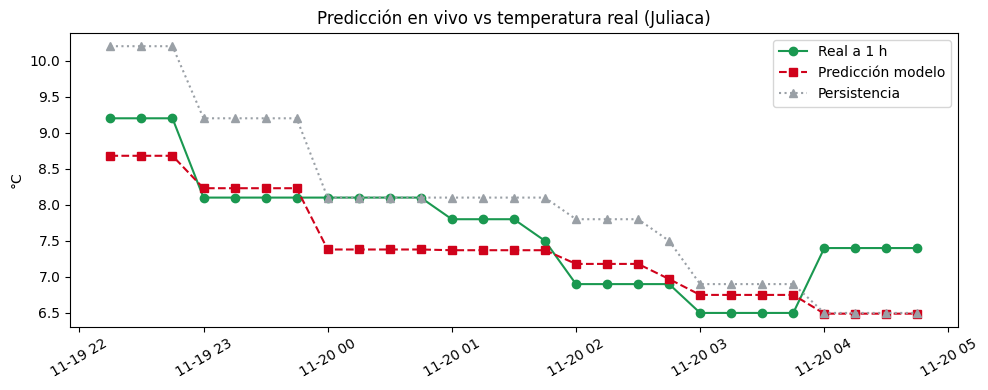

In [25]:
import matplotlib.pyplot as plt

print("Consulta activa:", consulta_pred.isActive, "|", consulta_pred.status["message"])
if consulta_pred.exception():
    print("ERROR:", consulta_pred.exception())

p = (spark.read.parquet(OUT_PRED)
     .select("hora_local", "temperatura", "temp_pred_1h")
     .dropDuplicates(["hora_local"]))
print("Predicciones guardadas (horas distintas):", p.count())

real = p.select((F.col("hora_local") - F.expr("INTERVAL 1 HOUR")).alias("hora_local"),
                F.col("temperatura").alias("temp_real_1h"))

cmp = (p.join(real, "hora_local")
        .withColumn("err_modelo", F.abs(F.col("temp_pred_1h") - F.col("temp_real_1h")))
        .withColumn("err_persist", F.abs(F.col("temperatura") - F.col("temp_real_1h")))
        .orderBy("hora_local"))

cmp.select("hora_local", "temperatura", "temp_pred_1h", "temp_real_1h",
           "err_modelo", "err_persist").show(40, truncate=False)

cmp.agg(F.count("*").alias("pares"),
        F.round(F.avg("err_modelo"), 3).alias("MAE_modelo"),
        F.round(F.avg("err_persist"), 3).alias("MAE_persistencia")).show()

pdf = cmp.toPandas()
plt.figure(figsize=(10, 4))
plt.plot(pdf["hora_local"], pdf["temp_real_1h"], "o-", label="Real a 1 h", color="#1a9850")
plt.plot(pdf["hora_local"], pdf["temp_pred_1h"], "s--", label="Predicción modelo", color="#d0021b")
plt.plot(pdf["hora_local"], pdf["temperatura"], "^:", label="Persistencia", color="#9aa0a6")
plt.title("Predicción en vivo vs temperatura real (Juliaca)")
plt.ylabel("°C"); plt.xticks(rotation=30); plt.legend(); plt.tight_layout(); plt.show()

## 19. Cierre: detener la consulta y resumen de artefactos

Se detiene la consulta de streaming de forma ordenada y se listan los productos de la sesión: el `PipelineModel` guardado y las predicciones en Parquet (entrada para S11).

In [26]:
consulta_pred.stop()
print("Consulta detenida. Activas:", [q.name for q in spark.streams.active])

import os
for ruta in ["./artifacts/modelo_rf_temp_h1", "./artifacts/predicciones_heladas"]:
    n = sum(len(f) for _, _, f in os.walk(ruta))
    print(f"{ruta}: {n} archivos")

print("Predicciones totales guardadas:", spark.read.parquet(OUT_PRED).count())

26/11/20 11:05:48 WARN DAGScheduler: Failed to cancel job group c7996a5c-dd08-4788-a86d-c816cc4240dd. Cannot find active jobs for it.
26/11/20 11:05:48 WARN DAGScheduler: Failed to cancel job group c7996a5c-dd08-4788-a86d-c816cc4240dd. Cannot find active jobs for it.


Consulta detenida. Activas: []
./artifacts/modelo_rf_temp_h1: 20 archivos
./artifacts/predicciones_heladas: 22 archivos
Predicciones totales guardadas: 31
